# CSE 190/251U — Homework 7 (coding problems)
Problems 4, 5 and 8 need code. Plots are saved as PNG files in this folder (`4a.png`, `4b.png`, `5a.png`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

rng = np.random.default_rng(0)
np.random.seed(0)

## Problem 4 — Length concentration
Draw 10,000 points from the spherical Gaussian $N(0, I_d)$ and plot a histogram of the squared lengths $\|X_i\|^2$.

In [2]:
def squared_lengths(d, n=10000):
    X = rng.standard_normal((n, d))
    return np.sum(X**2, axis=1)

def plot_lengths(d, fname):
    L = squared_lengths(d)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(L, bins=60, edgecolor='black', alpha=0.75)
    ax.axvline(L.mean(), color='red', linestyle='--', label=f'mean = {L.mean():.2f}')
    ax.set_xlabel(r'squared length $\|X\|^2$')
    ax.set_ylabel('count')
    ax.set_title(f'Squared lengths of 10,000 draws from $N(0, I_{{{d}}})$')
    ax.legend()
    fig.tight_layout()
    fig.savefig(fname, dpi=150)
    plt.show()
    print(f'd = {d}: mean = {L.mean():.3f}, std = {L.std():.3f}, '
          f'relative spread std/mean = {L.std()/L.mean():.3f}, '
          f'5%-95% range = [{np.percentile(L,5):.2f}, {np.percentile(L,95):.2f}]')
    return L

### 4(a) d = 10

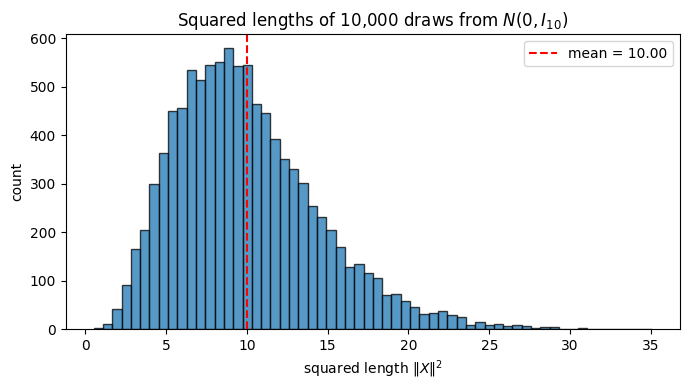

d = 10: mean = 10.003, std = 4.466, relative spread std/mean = 0.446, 5%-95% range = [3.95, 18.30]


In [3]:
L10 = plot_lengths(10, '4a.png')

**Answer 4(a):** For $d = 10$ the typical squared length is about **10** (sample mean ≈ 10.0, std ≈ 4.5). The squared length follows a $\chi^2_{10}$ distribution, so $E\|X\|^2 = d = 10$.

### 4(b) d = 100

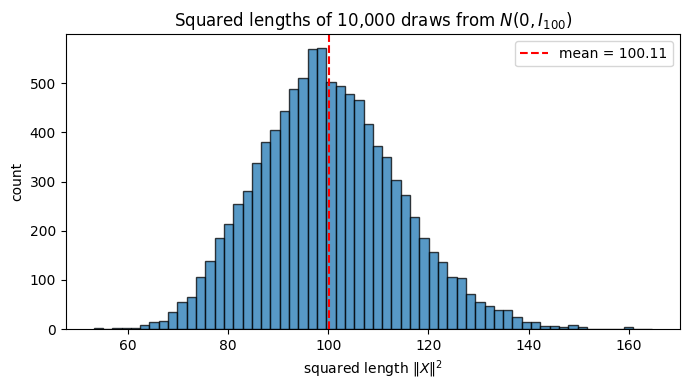

d = 100: mean = 100.105, std = 14.156, relative spread std/mean = 0.141, 5%-95% range = [77.83, 124.74]


In [4]:
L100 = plot_lengths(100, '4b.png')

**Answer 4(b):** For $d = 100$ the squared lengths center around **100** (std ≈ 14). The histogram is **more concentrated** than in (a) relative to its typical value: std/mean drops from about 0.45 to about 0.14. In general $E\|X\|^2 = d$ and $\mathrm{std} = \sqrt{2d}$, so the relative spread $\sqrt{2/d}$ shrinks as $d$ grows, and almost all points lie near the sphere of radius $\sqrt{d}$.

## Problem 5 — Chi-squared distribution
### 5(a) Density of the chi-squared distribution with 10 degrees of freedom

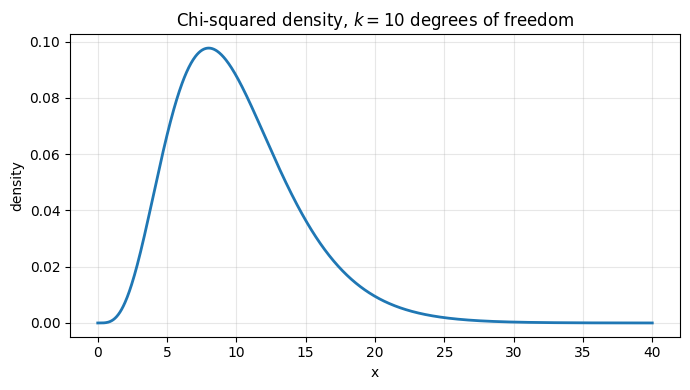

In [5]:
x = np.linspace(0, 40, 1000)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, chi2.pdf(x, df=10), linewidth=2)
ax.set_xlabel('x')
ax.set_ylabel('density')
ax.set_title(r'Chi-squared density, $k = 10$ degrees of freedom')
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig('5a.png', dpi=150)
plt.show()

**Answer 5(a):** The plot is above and saved as `5a.png`. The density is right-skewed, with its mode at $k-2 = 8$ and mean $k = 10$.

### 5(b) Estimate the median from 10,000 samples

In [6]:
samples = np.random.chisquare(df=10, size=10000)
print(f'Estimated median from 10,000 samples: {np.median(samples):.4f}')
print(f'Exact median (scipy chi2.median(10)): {chi2.median(10):.4f}')

Estimated median from 10,000 samples: 9.2715
Exact median (scipy chi2.median(10)): 9.3418


**Answer 5(b):** The median estimated from 10,000 samples is **≈ 9.27**. The exact value is $\approx 9.34$, a bit below the mean $k = 10$ because the distribution is right-skewed.

## Problem 8 — Modeling temperature data with a multivariate Gaussian
Columns: latitude, longitude, temperature (°C). Mean $\mu_i = 20$, covariance $\Sigma_{ij} = \exp(-\|z_i - z_j\|/\sigma)$ with $\sigma = 1.5$.

In [7]:
train = np.loadtxt('Data_gptrain.csv', delimiter=',')
test  = np.loadtxt('Data_gptest.csv',  delimiter=',')
z_tr, x_tr = train[:, :2], train[:, 2]
z_te, x_te = test[:, :2],  test[:, 2]
print(train.shape, test.shape)

sigma, mu = 1.5, 20.0
def kernel(A, B):
    D = np.linalg.norm(A[:, None, :] - B[None, :, :], axis=2)
    return np.exp(-D / sigma)

S_tr    = kernel(z_tr, z_tr)   # 93 x 93
S_te_tr = kernel(z_te, z_tr)   # 11 x 93
S_te    = kernel(z_te, z_te)   # 11 x 11

(93, 3) (11, 3)


### 8(a) Conditional mean $E[X_{te} \mid X_{tr} = x_{tr}] = \mu_{te} + \Sigma_{te,tr}\Sigma_{tr}^{-1}(x_{tr} - \mu_{tr})$

In [8]:
pred_gauss = mu + S_te_tr @ np.linalg.solve(S_tr, x_tr - mu)
mse_gauss = np.mean((pred_gauss - x_te)**2)
print(pd.DataFrame({'true x_te': x_te, 'Gaussian prediction': pred_gauss.round(3)}).to_string())
print(f'\nMSE of Gaussian conditional-mean predictions: {mse_gauss:.4f}')

    true x_te  Gaussian prediction
0        16.3               18.113
1        22.1               21.971
2        20.4               21.212
3        14.8               15.769
4        19.7               20.240
5        20.5               21.280
6        18.4               16.962
7        19.1               21.845
8        22.6               20.690
9        22.9               20.250
10       17.4               18.085

MSE of Gaussian conditional-mean predictions: 2.4132


**Answer 8(a):** The conditional mean $E[X_{te}\mid X_{tr}=x_{tr}] = 20 + \Sigma_{te,tr}\Sigma_{tr}^{-1}(x_{tr}-20)$ gives the 11 predictions in the table above. Their **mean squared error against the true $x_{te}$ is ≈ 2.41**.

### 8(b) Baseline: predict the average of $x_{tr}$ everywhere

In [9]:
pred_avg = np.full_like(x_te, x_tr.mean())
mse_avg = np.mean((pred_avg - x_te)**2)
print(f'Average training temperature: {x_tr.mean():.4f}')
print(f'MSE of naive average predictions: {mse_avg:.4f}')

Average training temperature: 18.9710
MSE of naive average predictions: 6.4228


**Answer 8(b):** Predicting the training average ($\bar{x}_{tr} \approx 18.97$°C) at all 11 test locations gives **MSE ≈ 6.42**. That is about 2.7× worse than the Gaussian conditional-mean predictions in (a).